<a href="https://colab.research.google.com/github/kelvin-yg98/Kelvin-Programming/blob/main/Monte_Carlo_Estimator_Simulations_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

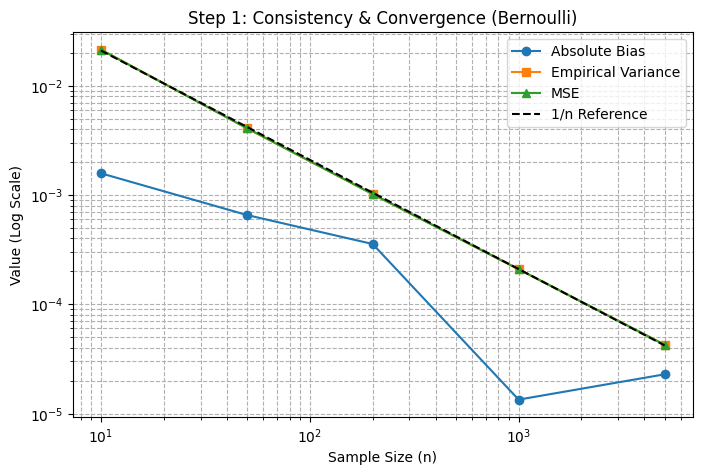

In [13]:
#Step 1: Consistency & Convergence (Bernoulli)


import matplotlib.pyplot as plt
import numpy as np

# Parameters
p = 0.3
n_values = [10, 50, 200, 1000, 5000]
R = 5000

biases = []
variances = []
mses = []

for n in n_values:
  # Simulate R samples of size n
  samples = np.random.binomial(1, p, size=(R, n))
  p_hats = np.mean(samples, axis=1)

  # Compute metrics
  biases.append(np.mean(p_hats) - p)
  variances.append(np.var(p_hats, ddof=1))
  mses.append(np.mean((p_hats - p) ** 2))

# Plot on log-log scale
plt.figure(figsize=(8, 5))
plt.loglog(n_values, np.abs(biases), "o-", label="Absolute Bias")
plt.loglog(n_values, variances, "s-", label="Empirical Variance")
plt.loglog(n_values, mses, "^-", label="MSE")
plt.loglog(
    n_values, [p * (1 - p) / n for n in n_values], "k--", label="1/n Reference"
)

plt.xlabel("Sample Size (n)")
plt.ylabel("Value (Log Scale)")
plt.title("Step 1: Consistency & Convergence (Bernoulli)")
plt.legend()
plt.grid(True, which="both", linestyle="--")
plt.show()

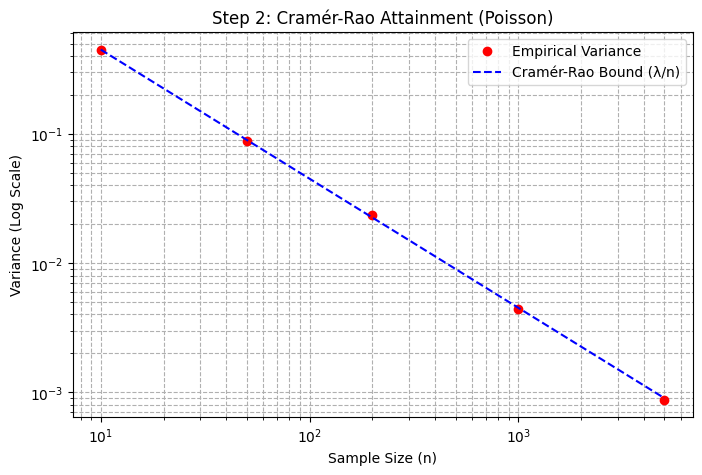

In [12]:
#Step 2: Cramér–Rao Attainment (Poisson)

import matplotlib.pyplot as plt
import numpy as np

# Parameters
lam = 4.5
n_values = [10, 50, 200, 1000, 5000]
R = 5000

empirical_vars = []
crlb_bounds = []

for n in n_values:
  samples = np.random.poisson(lam, size=(R, n))
  lambda_hats = np.mean(samples, axis=1)

  empirical_vars.append(np.var(lambda_hats, ddof=1))
  crlb_bounds.append(lam / n)

# Plot Empirical Variance vs CRLB
plt.figure(figsize=(8, 5))
plt.loglog(n_values, empirical_vars, "ro", label="Empirical Variance")
plt.loglog(
    n_values, crlb_bounds, "b--", label="Cramér-Rao Bound (\u03bb/n)"
)

plt.xlabel("Sample Size (n)")
plt.ylabel("Variance (Log Scale)")
plt.title("Step 2: Cramér-Rao Attainment (Poisson)")
plt.legend()
plt.grid(True, which="both", linestyle="--")
plt.show()

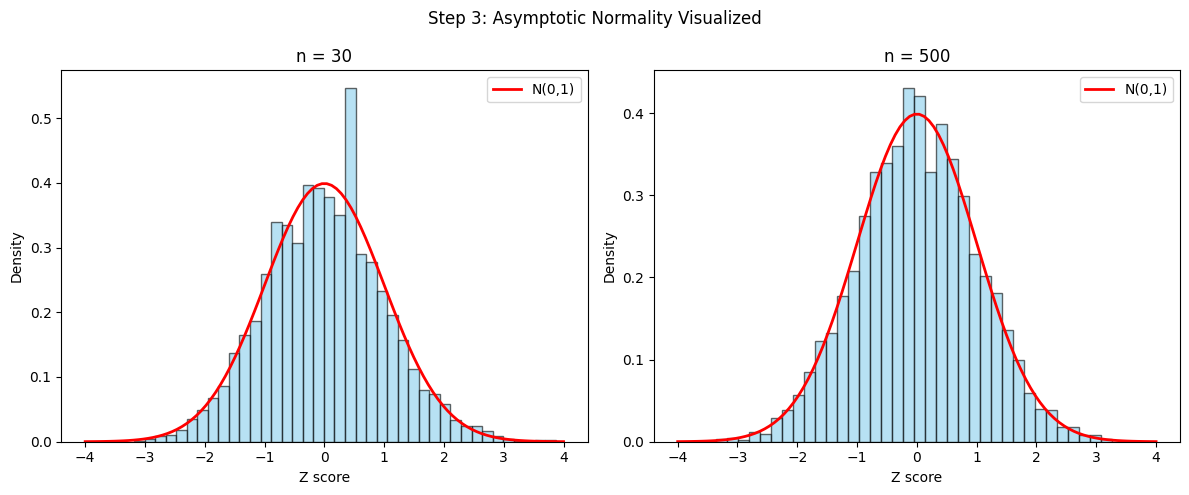

In [11]:
#Step 3: Asymptotic Normality Visualized

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

lam = 4.5
sample_sizes = [30, 500]
R = 5000

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, n in enumerate(sample_sizes):
  samples = np.random.poisson(lam, size=(R, n))
  lambda_hats = np.mean(samples, axis=1)

  # Standardize
  Z = np.sqrt(n) * (lambda_hats - lam) / np.sqrt(lam)

  # Plot Histogram
  axes[idx].hist(
      Z, bins=40, density=True, alpha=0.6, color="skyblue", edgecolor="black"
  )

  # Overlay N(0,1)
  x = np.linspace(-4, 4, 100)
  axes[idx].plot(x, norm.pdf(x), "r-", lw=2, label="N(0,1)")

  axes[idx].set_title(f"n = {n}")
  axes[idx].set_xlabel("Z score")
  axes[idx].set_ylabel("Density")
  axes[idx].legend()

plt.suptitle("Step 3: Asymptotic Normality Visualized")
plt.tight_layout()
plt.show()

In [10]:
#Step 4: Delta Method Check

import numpy as np

lambdas = [4.5, 10.0]
sample_sizes = [30, 500]
R = 5000

print("--- Step 4: Delta Method Verification ---")
print("Target Predicted Variance = 0.25 (1/4)\n")

for lam in lambdas:
  for n in sample_sizes:
    samples = np.random.poisson(lam, size=(R, n))
    lambda_hats = np.mean(samples, axis=1)

    # Transform using g(x) = sqrt(x)
    transformed = np.sqrt(n) * (np.sqrt(lambda_hats) - np.sqrt(lam))
    emp_var = np.var(transformed, ddof=1)

    print(
        f"lambda = {lam:<4} | n = {n:<3} | Empirical Variance = {emp_var:.4f}"
    )


--- Step 4: Delta Method Verification ---
Target Predicted Variance = 0.25 (1/4)

lambda = 4.5  | n = 30  | Empirical Variance = 0.2410
lambda = 4.5  | n = 500 | Empirical Variance = 0.2441
lambda = 10.0 | n = 30  | Empirical Variance = 0.2461
lambda = 10.0 | n = 500 | Empirical Variance = 0.2525


In [9]:
#Step 5: Coverage of a Confidence Interval

import numpy as np

p = 0.3
n = 200
R = 5000

# Simulate
samples = np.random.binomial(1, p, size=(R, n))
p_hats = np.mean(samples, axis=1)

# Standard Error & 95% Confidence Interval
se = np.sqrt(p_hats * (1 - p_hats) / n)
lower_bound = p_hats - 1.96 * se
upper_bound = p_hats + 1.96 * se

# Check if true p is inside interval
covered = (lower_bound <= p) & (p <= upper_bound)
coverage_rate = np.mean(covered) * 100

print("--- Step 5: CI Coverage Rate ---")
print(f"Target Nominal Coverage: 95.0%")
print(f"Empirical Coverage Rate: {coverage_rate:.2f}%")

--- Step 5: CI Coverage Rate ---
Target Nominal Coverage: 95.0%
Empirical Coverage Rate: 94.74%


In [15]:
# ==========================================
# Project Summary & Takeaways
# ==========================================
# - Consistency & Efficiency: As sample size (n) increases, estimator
#   variance decreases at a 1/n rate, confirming that the sample mean
#   efficiently utilizes data and achieves the Cramér-Rao lower bound.
# - Asymptotic Normality: Visualizing standardized estimators proved
#   the Central Limit Theorem in action—transforming non-normal Poisson
#   and Bernoulli data into a standard normal distribution (N(0,1)).
# - Transformations & Inference: The Delta method successfully stabilized
#   variance under non-linear transformations, and confidence interval
#   simulations confirmed a reliable 95% empirical coverage rate.